In [14]:
import pandas as pd
import matplotlib.pyplot as plt

crime = pd.read_csv("CrimeData.csv", sep=",")
crime.sample(10)


crimePerNeighborhood= dict()
numCrimeList= []

#filter out the neighborhoods that are just places outside of the city
crime= crime[crime['INCIDENTNEIGHBORHOOD'].str.contains("Outside", na=False)==False]
crime= crime[crime['INCIDENTNEIGHBORHOOD'].str.contains("Boro", na=False)==False]

#create a list of all the different neighborhoods so the number of crimes reported in each can be counted
neighborhoodList= crime['INCIDENTNEIGHBORHOOD'].dropna().unique()
#print(neighborhoodList)
for neighborhood in neighborhoodList:
    query_mask= crime['INCIDENTNEIGHBORHOOD'].str.contains(neighborhood, na=False)
    sepNeighborhoodList= crime[query_mask]

    numCrimeList.append(len(sepNeighborhoodList))
    crimePerNeighborhood[len(sepNeighborhoodList)]= neighborhood
    
    #print(neighborhood + ": " +str(len(sepNeighborhoodList)))

numCrimeList.sort()
print("10 Lowest Crime Neighborhoods")
i=0
while i<10:
    print(crimePerNeighborhood[numCrimeList[i]] + ": "+ str(numCrimeList[i]))
    i+=1
print("\n10 Highest Crime Neighborhoods")
i= len(numCrimeList)-1
while i>len(numCrimeList)-10:
    print(crimePerNeighborhood[numCrimeList[i]] + ": "+ str(numCrimeList[i]))
    i-=1

10 Lowest Crime Neighborhoods
Troy Hill-Herrs Island: 252
Ridgemont: 296
Chartiers City: 339
New Homestead: 353
East Carnegie: 401
Swisshelm Park: 443
Summer Hill: 523
Regent Square: 565
Hays: 569
Arlington Heights: 573

10 Highest Crime Neighborhoods
Central Business District: 19943
South Side Flats: 19098
Carrick: 11927
Shadyside: 8773
Bloomfield: 8704
East Liberty: 8451
Squirrel Hill South: 7809
Brookline: 7792
Mount Washington: 7723


Best: The least number of crimes reported in a neighborhood

The best overall is **Troy Hill-Herrs Island**

<function matplotlib.pyplot.show(close=None, block=None)>

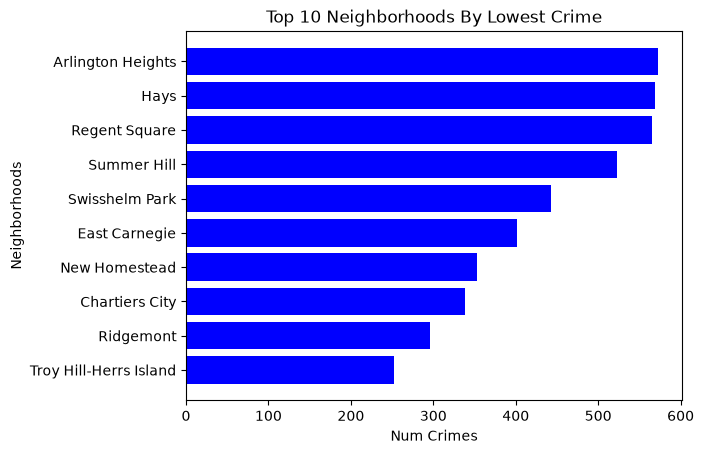

In [23]:
topTenNeighborhoods= []
i=0
while i<10:
    topTenNeighborhoods.append(crimePerNeighborhood[numCrimeList[i]])
    i+=1

values= list(numCrimeList[:10])
neighborhoods= list(topTenNeighborhoods)

plt.barh(neighborhoods,values, color='blue')
plt.xlabel('Num Crimes')
plt.ylabel('Neighborhoods')
plt.title('Top 10 Neighborhoods By Lowest Crime')
plt.show